# Complete measured dune radar profile: scalar-wave migration


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：gpr_dune_stolt_migration

**观测 y：** radar(1, 512, 1040)；time_ns(1, 512)；position_m(1, 1040)；topo_position_m(1, 36)；surface_elevation_m(1, 36)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 有符号初始反射波场。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 已知速度爆炸反射体波动方程的表面观测。本地路径为 `solvers.reconstruct→migrate(Stolt)`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 8, 9（cell编号按文件内从0计）。章节包括：# Complete measured dune radar profile: scalar-wave migration；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；### Observation and calibration inspection；；### Independent physical checks；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 真实地下介电常数GT不存在；迁移响应为条件波场。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Reconstruct a signed subsurface reflection image from a complete measured ground-penetrating radar profile despite diffraction, finite aperture, background arrivals and uncertain propagation geometry.



Reconstruct a signed subsurface reflection image from the complete real GSSI common-offset dune profile. Diffraction spreads an off-nadir reflector across multiple traces. The target is the initial exploding-reflector wavefield in receiver-count units, not an independently calibrated permittivity map. No actual subsurface truth exists for this task; the separate original-upstream result is a standard-method comparison.


## 2. Data

`data/raw_data.npz` contains all recorded radar samples and independently measured survey geometry:

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| radar | (1, 512, 1040) | float64 | Signed receiver amplitudes in instrument counts; axes batch, recorded time, profile trace. Original integer values are preserved exactly in float64. |
| time_ns | (1, 512) | float64 | Recorded time coordinates in ns, including the instrument delay. |
| position_m | (1, 1040) | float64 | Trace positions in m along the profile, with first trace at zero. |
| topo_position_m | (1, 36) | float64 | Along-profile positions in m of independently surveyed surface-elevation stations. |
| surface_elevation_m | (1, 36) | float64 | Surface elevation in m in the source survey's vertical datum, paired with topo_position_m. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Recorded time window | 0.0 to 48.0 | ns | 512 sampled times, both endpoints included in the supplied coordinates. |
| Sampling interval | 0.09393346379647749 | ns | Preserved float64 interval of the supplied time axis. |
| Trace density | 50.0 | traces/m | GSSI acquisition-header spatial calibration. |
| Trace spacing | 0.02 | m | Uniform physical spacing derived from trace density. |
| Complete trace count | 1040 | traces | Entire measured line, with x from 0 to 20.78 m. |
| Instrument time delay t0 | 5.0 | ns | Fixed nominal arrival-time calibration used for continuous time-zero resampling. |
| Background wave velocity v | 140000000.0 | m/s | Selected homogeneous-background model, equivalent to 0.14 m/ns; not a measured permittivity map. |
| Output depth spacing | 0.006575342465753425 | m | Half the nominal velocity times the time interval in seconds. |
| Coordinates | x along profile, z downward | dimensionless | Nominal planar imaging coordinates; elevation is upward in the independent survey datum. |
| Offset model | Zero-offset approximation | dimensionless | Treat transmitter and receiver as coincident for this scalar migration. |
| Noise calibration | Unavailable | counts | No independent sample-wise variance or noise-free radargram is supplied. |
| Boundary model | Finite aperture, periodic Fourier transform | dimensionless | Linear edge weighting precedes migration; temporal spectral interpolation uses the stated endpoint-extension convention. |

Surface elevation is independent acquisition geometry, not an estimate from the unknown subsurface. A vertical display shift using it does not correct wave propagation for topography or lateral velocity variation.


## 3. Physics



The exploding-reflector field obeys $P_{tt}=(v/2)^2(P_{xx}+P_{zz})$, where P is the wavefield, v the physical two-way propagation velocity, x along-profile distance, z depth, and t corrected time. The surface field is observed, and the image is $I(x,z)=P(x,z,0)$. In frequency space, $omega_*=(v/2)sqrt{k_x^2+k_z^2}$ maps temporal angular frequency to vertical wavenumber; the migrated spectrum is $k_z/sqrt{k_x^2+k_z^2}$ times the measured spectrum sampled at that frequency. Spatial/temporal units are metres/seconds, and output depth sampling is z=vt/2. Homogeneous planar propagation is an approximation to the surveyed sloping surface.


## 4. Method


Remove per-trace DC and the common mean trace after exact5ns linear delay interpolation. Apply the selected linear100-trace/40-time-sample edge taper, transform, explicitly interpolate each fixed-kx column, apply obliquity and the source DC/Nyquist conventions, and inverse transform. We actively compute0.12/0.14/0.16m/ns hypotheses and a zero-outside-band diagnostic. The required output is the0.14m/ns source-convention field. Endpoint extension for requests above measured Nyquist is an explicit numerical boundary approximation; its energetic and image effects are quantified below rather than described as a strict bandlimited wave operator.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


### Observation and calibration inspection

The public acquisition contains all512×1040 recorded samples, original signed instrument amplitude preserved in float64, recorded times0..48ns, trace positions0..20.78m at0.02m spacing, and36 independent surveyed surface elevations. Nominal background velocity is0.14m/ns and time delay5ns. Continuous linear time-zero resampling keeps that calibration rather than rounding it to an acquired sample. This task applies the original ImpDAR Stolt kernel to a separate real GPRPy acquisition; it is not a claim to reproduce either paper's complete processing figures. The separately licensed CREWES/irlib kernel is not used.

The ImpDAR paper compares Kirchhoff, frequency-wavenumber, phase-shift and time-wavenumber migration on a different glacier acquisition. Those broader paper experiments are not silently represented by missing-method placeholders here: this task deliberately selects the Stolt inverse on this bound dune acquisition, with actively computed velocity, bandwidth and terrain comparisons. The GPRPy source demonstration's terrain context is retained through the supplied independent survey.


In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,load_topography,prepare,VELOCITY_M_S
from src.solvers import reconstruct,boundary_diagnostics
from src.visualization import review
raw,time_ns,x=load_data();station,elevation=load_topography()
t=time.perf_counter();fresh,diagnostics=reconstruct(raw,time_ns,return_diagnostics=True);runtime=time.perf_counter()-t
low=reconstruct(raw,time_ns,1.2e8);high=reconstruct(raw,time_ns,1.6e8)
bandlimited=reconstruct(raw,time_ns,bandlimited=True)
prepared=prepare(raw,time_ns)[-1]
dz=(time_ns[1]-time_ns[0])*1e-9*VELOCITY_M_S/2
boundary=boundary_diagnostics(diagnostics)
boundary['relative_image_l2_difference']=float(np.linalg.norm(fresh-bandlimited)/np.linalg.norm(fresh))
boundary['range_normalized_image_rmse']=float(np.sqrt(np.mean((fresh-bandlimited)**2))/np.ptp(fresh))
boundary['max_absolute_image_difference_counts']=float(abs(fresh-bandlimited).max())
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh[None])
np.savez_compressed('notebooks/reference_outputs/cleaned_measurements.npz',reconstruction=fresh[None],low_velocity=low[None],high_velocity=high[None],bandlimited=bandlimited[None],runtime_s=runtime)
upstream=np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False)
print(f'Fresh complete {raw.shape} acquisition -> {fresh.shape} migration: {runtime:.6f}s')
print(json.dumps(boundary,indent=2))

Fresh complete (512, 1040) acquisition -> (458, 1040) migration: 0.067056s
{
  "unsupported_grid_fraction": 0.020656354515050167,
  "unsupported_migrated_energy_fraction": 4.983924646640737e-07,
  "last_measured_frequency_energy_fraction": 9.784685199529186e-08,
  "relative_image_l2_difference": 0.0007059691669358328,
  "range_normalized_image_rmse": 2.9671960731516316e-05,
  "max_absolute_image_difference_counts": 23.18485085132905
}



The acquisition/preparation/image comparison preserves signed amplitudes. The numerical upstream residual is displayed at its own very small scale, while the bandlimited-minus-source-boundary difference is explicitly a different numerical convention, not a failed implementation. Display clipping is only a colour limit and never modifies scored arrays.

Velocity hypotheses use a common explicitly labelled nominal0.14m/ns depth axis so that focusing changes are not concealed by rescaling each image. The terrain panel uses the independent surveyed elevation through source-compatible PCHIP interpolation and integer-depth row shifts after migration. It is a display of the selected planar image, not a terrain-aware wave-equation inverse. The NaN exterior is unobserved display support, not part of the finite required submission.


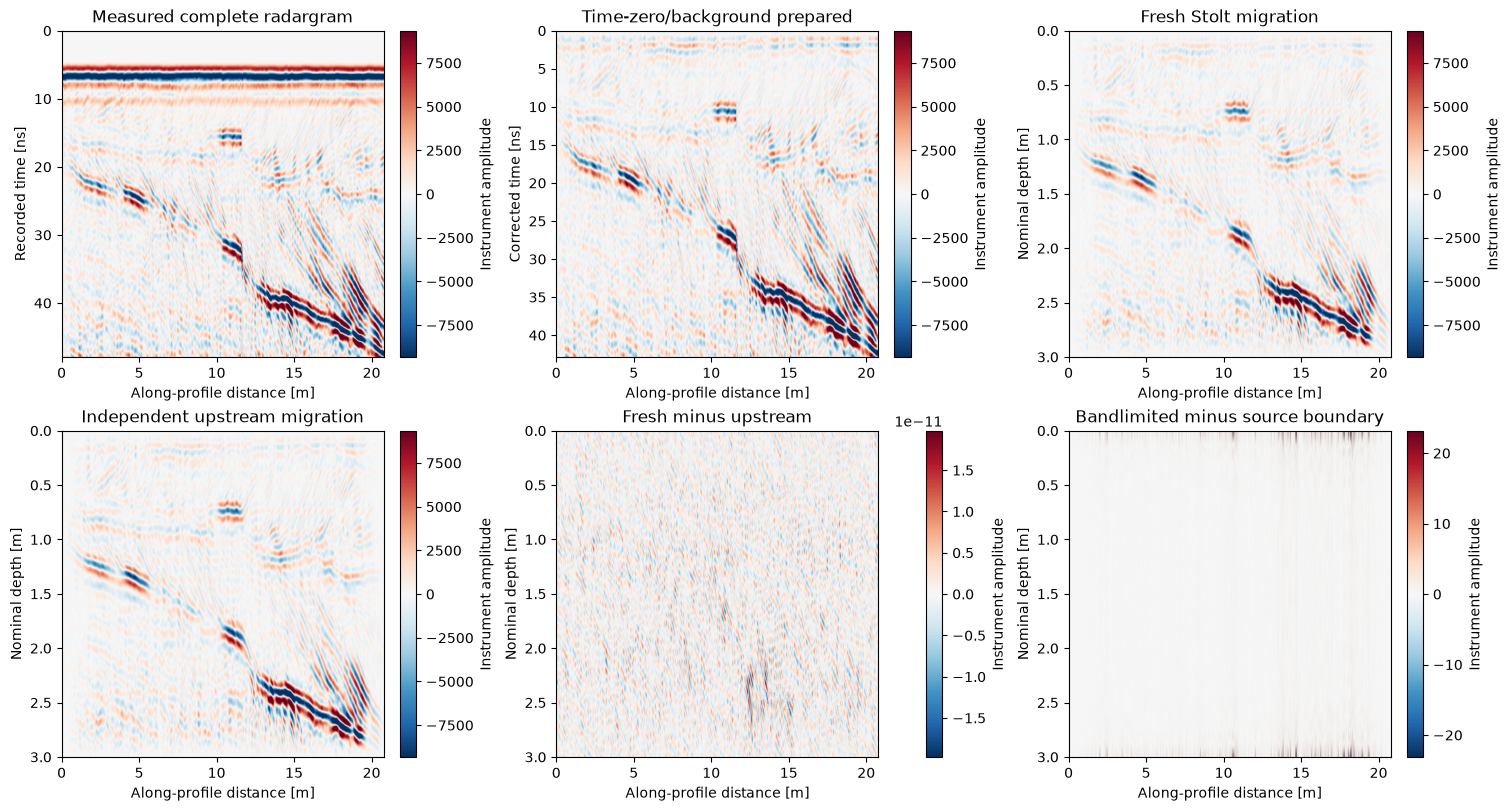

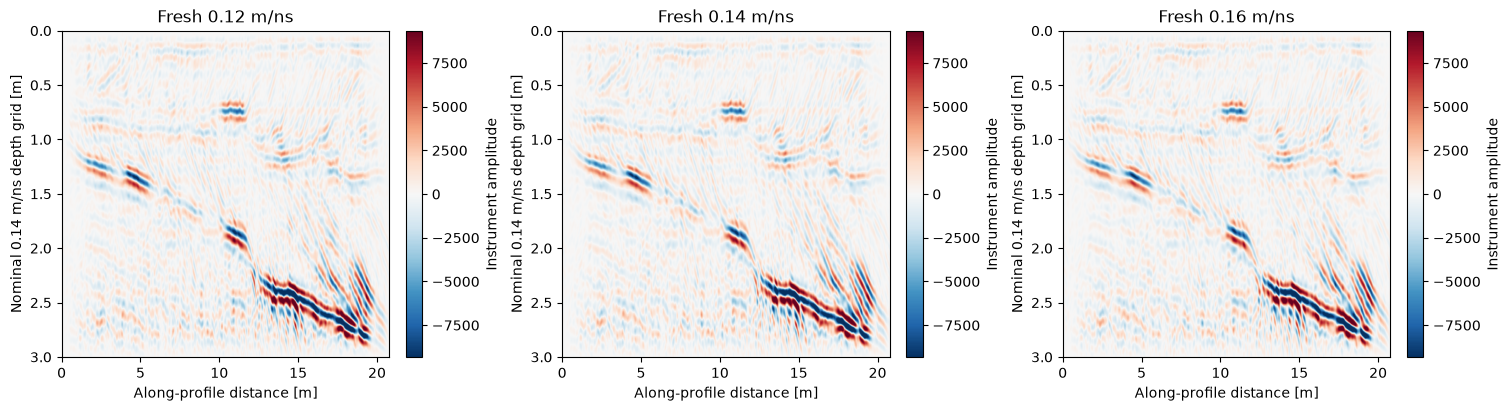

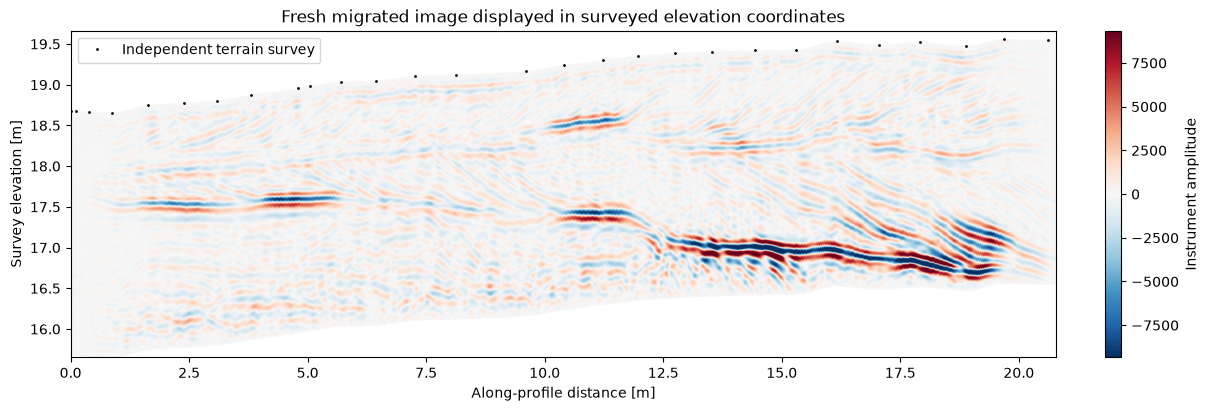

In [2]:
fig_acquisition,fig_velocity,fig_terrain=review(raw,time_ns,x,prepared,fresh,upstream['reconstruction'][0],low,high,bandlimited,dz,station,elevation)
plt.show()

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0,
    "nrmse": 7.158318914645772e-17
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    }
  },
  "errors": []
}
Method | NCC vs independent upstream 0.14 | Dynamic-range NRMSE | RMS amplitude
Independent upstream 0.14 | 1.0 | 0.0 | 1657.7546001096912
Fresh source convention 0.14 | 1.0 | 7.158318914645772e-17 | 1657.7546001096914
Fresh 0.12 | 0.9462572243534222 | 0.013831267006752059 | 1669.4499766021186
Fresh 0.16 | 0.9393279209362301 | 0.01455440979194264 | 1635.8175845522967
Fresh zero-outside-band 0.14 | 0.9999997508037369 | 2.967196073151635e-05 | 1657.7541870034393
Maximum full-image upstream differences for each velocity:
0.12 2.4556356947869062e-11
0.14 1.978150976356119e-11
0.16 2.091837814077735e-11


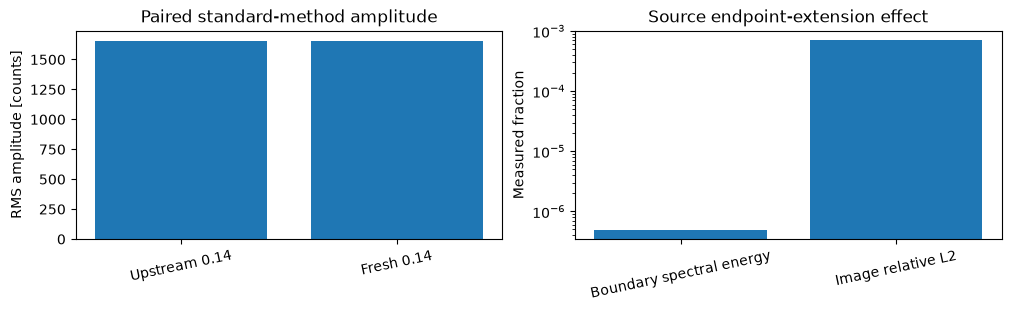

In [3]:
spec=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,status=judge.evaluate('output/reconstruction.npz');assert status==0,report
print(json.dumps(report,indent=2))
print('Method | NCC vs independent upstream 0.14 | Dynamic-range NRMSE | RMS amplitude')
methods=[('Independent upstream 0.14',upstream['reconstruction'][0]),('Fresh source convention 0.14',fresh),('Fresh 0.12',low),('Fresh 0.16',high),('Fresh zero-outside-band 0.14',bandlimited)]
for label,a in methods:
    measured=judge.metrics(a,upstream['reconstruction'][0])
    print(label,'|',measured['ncc'],'|',measured['nrmse'],'|',np.sqrt(np.mean(a*a)))
print('Maximum full-image upstream differences for each velocity:')
for label,a,key in [('0.12',low,'low_velocity'),('0.14',fresh,'reconstruction'),('0.16',high,'high_velocity')]:print(label,float(abs(a-upstream[key][0]).max()))
fig,axes=plt.subplots(1,2,figsize=(10,3),layout='constrained')
axes[0].bar(['Upstream 0.14','Fresh 0.14'],[np.sqrt(np.mean(upstream['reconstruction'][0]**2)),np.sqrt(np.mean(fresh**2))]);axes[0].set(title='Paired standard-method amplitude',ylabel='RMS amplitude [counts]')
axes[1].bar(['Boundary spectral energy','Image relative L2'],[boundary['unsupported_migrated_energy_fraction'],boundary['relative_image_l2_difference']]);axes[1].set(yscale='log',title='Source endpoint-extension effect',ylabel='Measured fraction')
for ax in axes:ax.tick_params(axis='x',rotation=12)
plt.show()

### Independent physical checks

The tests additionally check two-way point-diffraction travel time and focusing at the known point, vertical-incidence sinusoid identity away from removed DC/Nyquist bins, the scalar dispersion relation, complex interpolation-adjoint dot product, linearity and background-removal identities. These cases are independent analytic checks, not expected arrays generated by the cleaned function under test. Original-upstream numeric captures separately cover full raw/preprocessing/Fourier/remap/three-velocity image/terrain-display parity.


## 6. Conclusion


The fresh explicit local Stolt implementation reproduces the original standard method on the complete real acquisition, with the full scientific context of velocity sensitivity, terrain display and numerical spectral-boundary approximation retained. The measured unsupported-band energy is about5×10⁻⁷ of migrated spectral energy and its image difference about7×10⁻⁴ in relativeL2. Those small nonzero differences are acknowledged rather than relabelled exact bandlimited physics. Material velocity uncertainty, finite aperture, pulse/gain effects, surface slope and the absence of subsurface truth remain physical limitations; NCC/NRMSE measure reference reproducibility only.

The velocity hypotheses deliberately share the nominal depth axis. Terrain row shifts are a post-migration display, not a topography-aware inverse. The quantified unsupported-band difference limits the source spectral-boundary approximation without implying independently known subsurface truth.
